 ## 3-3 · DuckDB를 이용한 로컬 대용량 데이터 처리

 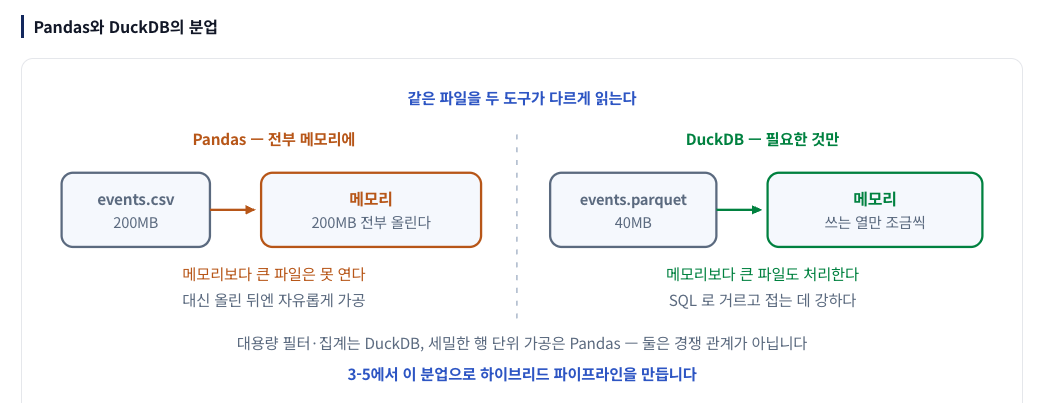
 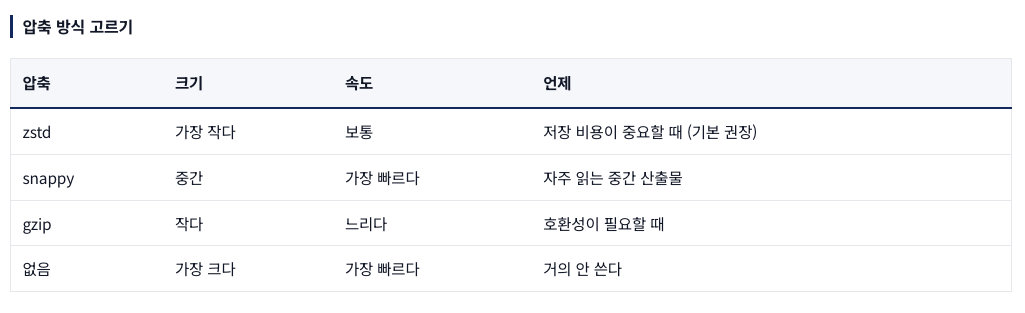

In [1]:
import numpy as np
import pandas as pd
 
rng = np.random.default_rng(42)
n = 1_000_000
 
events = pd.DataFrame({
    'event_id': np.arange(n),
    'user_id': rng.integers(1, 50_001, n),
    'event_type': rng.choice(['view', 'cart', 'buy'], n, p=[0.8, 0.15, 0.05]),
    'value': rng.integers(1, 100, n) * 100,
    'ts': pd.to_datetime('2026-06-01')
        + pd.to_timedelta(rng.integers(0, 60 * 24 * 3600, n), unit='s'),
})
events.to_csv('events.csv', index=False)
print('생성 완료:', len(events), '행')

생성 완료: 1000000 행


In [ ]:
! ls -lh events.csv


-rw-r--r--@ 1 hyunjunson  staff    41M 10월 18 17:45 events.csv


In [ ]:
# query.py — 3~6단계를 이 파일에 이어 붙입니다
import duckdb
import pandas as pd

print(duckdb.sql("""
    SELECT event_type, count(*) AS cnt, sum(value) AS total
    FROM 'events.csv'
    GROUP BY event_type
    ORDER BY cnt DESC
"""))

┌────────────┬────────┬────────────┐
│ event_type │  cnt   │   total    │
│  varchar   │ int64  │   int128   │
├────────────┼────────┼────────────┤
│ view       │ 799932 │ 4000853300 │
│ cart       │ 150025 │  749601000 │
│ buy        │  50043 │  249909000 │
└────────────┴────────┴────────────┘



In [4]:
duckdb.sql("DESCRIBE SELECT * FROM 'events.csv'")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ event_id    │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ user_id     │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ event_type  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ value       │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ts          │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [5]:
duckdb.sql("SELECT * FROM 'events.csv' LIMIT 5")

┌──────────┬─────────┬────────────┬───────┬─────────────────────┐
│ event_id │ user_id │ event_type │ value │         ts          │
│  int64   │  int64  │  varchar   │ int64 │      timestamp      │
├──────────┼─────────┼────────────┼───────┼─────────────────────┤
│        0 │    4463 │ view       │  5700 │ 2026-07-16 03:28:19 │
│        1 │   38698 │ view       │  8400 │ 2026-06-10 23:02:55 │
│        2 │   32729 │ view       │  9500 │ 2026-06-10 08:17:19 │
│        3 │   21944 │ view       │  6000 │ 2026-07-01 20:47:26 │
│        4 │   21651 │ view       │   900 │ 2026-06-10 23:39:14 │
└──────────┴─────────┴────────────┴───────┴─────────────────────┘

In [6]:
duckdb.sql("SELECT count(*) FROM 'events.csv'")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1000000 │
└──────────────┘

In [ ]:
duckdb.sql("""
    SELECT count(*) FROM 'events.csv' WHERE event_type = 'buy'
""")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        50043 │
└──────────────┘

In [10]:
duckdb.sql("""
SELECT date_trunc('day', ts) AS d,
event_type,
sum(value) AS total
FROM 'events.csv'
GROUP BY 1, 2
"""
    )

┌─────────────────────┬────────────┬──────────┐
│          d          │ event_type │  total   │
│      timestamp      │  varchar   │  int128  │
├─────────────────────┼────────────┼──────────┤
│ 2026-07-02 00:00:00 │ view       │ 65840300 │
│ 2026-06-19 00:00:00 │ view       │ 66003600 │
│ 2026-06-14 00:00:00 │ view       │ 66231100 │
│ 2026-07-26 00:00:00 │ view       │ 66930100 │
│ 2026-06-10 00:00:00 │ cart       │ 12874200 │
│ 2026-07-11 00:00:00 │ view       │ 67005800 │
│ 2026-06-25 00:00:00 │ view       │ 66979900 │
│ 2026-07-16 00:00:00 │ view       │ 67206800 │
│ 2026-07-08 00:00:00 │ view       │ 66335200 │
│ 2026-06-21 00:00:00 │ cart       │ 12340200 │
│          ·          │  ·         │     ·    │
│          ·          │  ·         │     ·    │
│          ·          │  ·         │     ·    │
│ 2026-07-11 00:00:00 │ cart       │ 12276700 │
│ 2026-07-16 00:00:00 │ cart       │ 11963300 │
│ 2026-06-04 00:00:00 │ cart       │ 12511900 │
│ 2026-07-18 00:00:00 │ buy        │  44

In [11]:
duckdb.sql("""
    WITH daily AS (
        SELECT date_trunc('day', ts) AS d,
               event_type,
               sum(value) AS total
        FROM 'events.csv'
        GROUP BY 1, 2
    )
    SELECT d, event_type, total,
           sum(total) OVER (PARTITION BY event_type ORDER BY d) AS running
    FROM daily
    ORDER BY event_type, d
    LIMIT 6
""")

┌─────────────────────┬────────────┬─────────┬──────────┐
│          d          │ event_type │  total  │ running  │
│      timestamp      │  varchar   │ int128  │  int128  │
├─────────────────────┼────────────┼─────────┼──────────┤
│ 2026-06-01 00:00:00 │ buy        │ 4064300 │  4064300 │
│ 2026-06-02 00:00:00 │ buy        │ 4307800 │  8372100 │
│ 2026-06-03 00:00:00 │ buy        │ 4148000 │ 12520100 │
│ 2026-06-04 00:00:00 │ buy        │ 4375800 │ 16895900 │
│ 2026-06-05 00:00:00 │ buy        │ 4027700 │ 20923600 │
│ 2026-06-06 00:00:00 │ buy        │ 4056700 │ 24980300 │
└─────────────────────┴────────────┴─────────┴──────────┘

In [14]:
df = duckdb.sql("""
    SELECT event_type, count(*) AS cnt, avg(value) AS avg_value
    FROM 'events.csv'
    GROUP BY event_type
    ORDER BY cnt DESC
                """)
print(type(df))

<class '_duckdb.DuckDBPyRelation'>


In [16]:
type(df.df())
df = df.df()

df.dtypes

event_type        str
cnt             int64
avg_value     float64
dtype: object

In [17]:
orders = pd.read_parquet('orders_enriched.parquet')
orders

,order_id,customer_id,category,price,quantity,order_date,amount,year,month,weekday,region,joined
0,1,18,의류,155000.0,2,2026-06-12,310000.0,2026,6,Friday,광주,2025-01-01 00:00:00.000000129
1,2,155,의류,134000.0,5,2026-06-03,670000.0,2026,6,Wednesday,부산,2025-01-01 00:00:00.000000255
2,3,131,도서,186000.0,1,2026-07-08,186000.0,2026,7,Wednesday,경기,2025-01-01 00:00:00.000000331
3,4,88,가전,192000.0,3,2026-07-11,576000.0,2026,7,Saturday,광주,2025-01-01 00:00:00.000000320
4,5,87,식품,141000.0,5,2026-07-17,705000.0,2026,7,Friday,광주,2025-01-01 00:00:00.000000345
...,...,...,...,...,...,...,...,...,...,...,...,...
1010,812,176,도서,89000.0,2,2026-07-09,178000.0,2026,7,Thursday,경기,2025-01-01 00:00:00.000000007
1011,77,67,도서,22000.0,5,2026-06-20,110000.0,2026,6,Saturday,서울,2025-01-01 00:00:00.000000050
1012,637,48,가전,108000.0,5,2026-06-16,540000.0,2026,6,Tuesday,서울,2025-01-01 00:00:00.000000187
1013,974,95,가전,52000.0,4,2026-06-04,208000.0,2026,6,Thursday,서울,2025-01-01 00:00:00.000000090


In [18]:
duckdb.sql("""
    SELECT region, count(*) AS cnt, sum(amount) AS total
    FROM orders            -- 파이썬 변수 이름을 그대로 씁니다
    GROUP BY region
    ORDER BY total DESC
""")

┌─────────┬───────┬────────────┐
│ region  │  cnt  │   total    │
│ varchar │ int64 │   double   │
├─────────┼───────┼────────────┤
│ 부산    │   276 │ 77389000.0 │
│ 경기    │   254 │ 72923000.0 │
│ 서울    │   235 │ 69007000.0 │
│ 광주    │   250 │ 68667000.0 │
└─────────┴───────┴────────────┘

In [19]:
import os
import time
import duckdb
 
duckdb.sql("""
    COPY (SELECT * FROM 'events.csv')
    TO 'events.parquet' (FORMAT parquet, COMPRESSION zstd)
""")
print('변환 완료')

변환 완료


In [20]:
! ls -lh events.csv events.parquet


-rw-r--r--@ 1 hyunjunson  staff    41M 10월 18 17:45 events.csv
-rw-r--r--@ 1 hyunjunson  staff   9.8M 10월 18 20:21 events.parquet


In [21]:
# 2단계 — speed.py 끝에 이어 붙입니다
csv = os.path.getsize('events.csv')
pq = os.path.getsize('events.parquet')
print(f'CSV    : {csv/1024/1024:,.1f} MB')
print(f'Parquet: {pq/1024/1024:,.1f} MB')
print(f'비율   : {pq/csv:.1%}  ({csv/pq:.1f}배 작아짐)')

CSV    : 40.6 MB
Parquet: 9.8 MB
비율   : 24.2%  (4.1배 작아짐)


In [22]:
# 3단계 — speed.py 끝에 이어 붙입니다
def bench(sql, rounds=3):
    times = []
    for _ in range(rounds):
        t0 = time.perf_counter()
        duckdb.sql(sql).fetchall()
        times.append(time.perf_counter() - t0)
    return sum(times) / len(times)

csv_t = bench("SELECT event_type, sum(value) FROM 'events.csv' GROUP BY event_type")
pq_t  = bench("SELECT event_type, sum(value) FROM 'events.parquet' GROUP BY event_type")

print(f'CSV     질의: {csv_t:.3f} 초')
print(f'Parquet 질의: {pq_t:.3f} 초')
print(f'차이        : {csv_t/pq_t:.1f}배')

CSV     질의: 0.118 초
Parquet 질의: 0.003 초
차이        : 35.3배


In [23]:
# 4단계 — speed.py 끝에 이어 붙입니다
# 먼저 일부러 틀린 비교 — 「전부 읽기」를 count(*) 로 잽니다
one_col = bench("SELECT sum(value) FROM 'events.parquet'")
all_cnt = bench("SELECT count(*) FROM (SELECT * FROM 'events.parquet')")
print(f'한 열만            : {one_col:.4f} 초')
print(f'전부 읽기(count(*)): {all_cnt:.4f} 초')



한 열만            : 0.0109 초
전부 읽기(count(*)): 0.0084 초


In [25]:
# 다섯 열을 정말로 읽게 합니다 — 열마다 집계를 하나씩
five = "SELECT max(event_id), max(user_id), max(event_type), sum(value), max(ts) FROM "
all_col = bench(five + "'events.parquet'")
print(f'다섯 열 전부       : {all_col:.4f} 초  (한 열의 {all_col/one_col:.1f}배)')


다섯 열 전부       : 0.0301 초  (한 열의 2.8배)


In [26]:
csv_one = bench("SELECT sum(value) FROM 'events.csv'")
csv_all = bench(five + "'events.csv'")
print(f'\nCSV 한 열만  : {csv_one:.3f} 초')
print(f'CSV 다섯 열  : {csv_all:.3f} 초')


CSV 한 열만  : 0.120 초
CSV 다섯 열  : 0.117 초


In [27]:
# 5단계 — speed.py 끝에 이어 붙입니다
for comp in ['zstd', 'snappy', 'gzip']:
    out = f'events_{comp}.parquet'
    duckdb.sql(f"COPY (SELECT * FROM 'events.csv') TO '{out}' (FORMAT parquet, COMPRESSION {comp})")
    size = os.path.getsize(out) / 1024 / 1024
    t = bench(f"SELECT event_type, sum(value) FROM '{out}' GROUP BY event_type")
    print(f'{comp:8s}  {size:6.1f} MB   {t:.3f} 초')

zstd         9.8 MB   0.002 초
snappy      15.9 MB   0.003 초
gzip        10.6 MB   0.003 초


In [30]:
duckdb.sql("""
    COPY (SELECT *, CAST(ts AS DATE) AS day FROM 'events.csv')
    TO 'events_parted'
    (FORMAT parquet, PARTITION_BY (event_type), COMPRESSION zstd, OVERWRITE_OR_IGNORE)
""")
print('파티션 저장 완료')



파티션 저장 완료


In [31]:
!find events_parted -type f | head
!du -sh events_parted

events_parted/event_type=view/data_0.parquet
events_parted/event_type=cart/data_0.parquet
events_parted/event_type=buy/data_0.parquet
 10M	events_parted


In [ ]:
parted = bench("SELECT sum(value) FROM 'events_parted/*/*.parquet' WHERE event_type = 'buy'")
single = bench("SELECT sum(value) FROM 'events.parquet' WHERE event_type = 'buy'")
print(f'파티션됨 : {parted:.4f} 초')
print(f'단일 파일: {single:.4f} 초')

파티션됨 : 0.0020 초
단일 파일: 0.0032 초


In [33]:
import duckdb
 
duckdb.sql("""
    COPY (SELECT * FROM 'events.csv')
    TO 'events_parted'
    (FORMAT parquet, PARTITION_BY (event_type), COMPRESSION zstd)
""")

IOException: IO Error: Directory "events_parted" is not empty! Enable OVERWRITE option to overwrite files

## 3-3 실측 기록 (본인 환경)
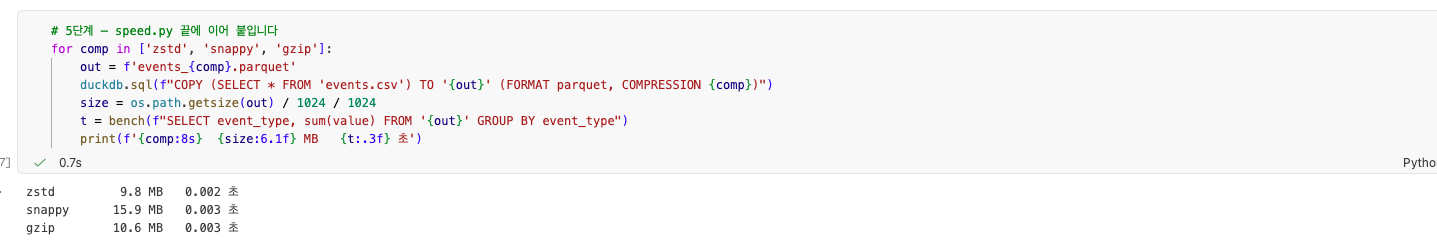

In [35]:
!cd /Users/hyunjunson/study/data-eng/week3
!ls -lh events.parquet orders_step1.parquet customers.csv orders_enriched.parquet

-rw-r--r--@ 1 hyunjunson  staff   7.9K 10월 11 14:08 customers.csv
-rw-r--r--@ 1 hyunjunson  staff   9.8M 10월 18 20:21 events.parquet
-rw-r--r--@ 1 hyunjunson  staff    24K 10월 11 15:29 orders_enriched.parquet
-rw-r--r--@ 1 hyunjunson  staff    21K 10월  9 14:54 orders_step1.parquet
